# 04 — Comparative Analysis

Compares the four metric families (ROUGE, BERTScore, NLI, LLM-as-a-Judge) using only the per-response scores already saved on Drive. **No metric model is re-run and no GPU is needed** (leave the runtime on CPU to save GPU quota).

Sections:
- **A. Inspect and align** the saved score files against the canonical evaluation dataframe and split.
- **B. Per-task-type comparison** (ROC-AUC / PR-AUC for Data2txt, QA, Summary).
- **C. Paired significance tests** between metrics on the same test examples.
- **D. Zero-training hybrid** score.
- **E. Final tables** for the paper.

The canonical split (`ragtruth_split_assignment.csv`) is loaded, never re-created.

## A1 — Inspect the saved files

This cell changes nothing. It prints what is actually in each saved file so the later cells use the real column names.

In [1]:

import os
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')
DRIVE_DIR = '/content/drive/MyDrive/rag-eval-metrics'

print('Files in the Drive folder:')
for f in sorted(os.listdir(DRIVE_DIR)):
    print('  ', f)

eval_df = pd.read_csv(
    f'{DRIVE_DIR}/ragtruth_eval_dataframe.csv',
    usecols=['id', 'task_type', 'has_hallucination']
)
split_df = pd.read_csv(f'{DRIVE_DIR}/ragtruth_split_assignment.csv')

ref = eval_df.merge(split_df, on='id', how='outer', indicator=True)
print('\nReference (eval dataframe + canonical split):', ref.shape,
      '| ids only in one file:', int((ref['_merge'] != 'both').sum()),
      '| duplicate ids:', int(ref['id'].duplicated().sum()))
print(ref['split'].value_counts().to_dict())
ref = ref.drop(columns='_merge')

SCORE_FILES = {
    'ROUGE': 'ragtruth_rouge_scores.csv',
    'BERTScore': 'ragtruth_bertscore_scores.csv',
    'NLI': 'ragtruth_nli_response_scores.csv',
    'LLM judge': 'ragtruth_llmjudge_scores.csv',
}

for name, fname in SCORE_FILES.items():
    path = f'{DRIVE_DIR}/{fname}'
    print('\n' + '=' * 70)
    print(name, '->', fname)
    if not os.path.exists(path):
        print('  FILE NOT FOUND')
        continue

    df = pd.read_csv(path)
    print('  shape:', df.shape)
    print('  columns:', df.columns.tolist())

    if 'id' not in df.columns:
        print('  NO id COLUMN')
        continue

    print('  duplicate ids:', int(df['id'].duplicated().sum()),
          '| ids missing vs reference:', len(set(ref['id']) - set(df['id'])),
          '| extra ids:', len(set(df['id']) - set(ref['id'])))

    m = df.merge(ref, on='id', how='inner', suffixes=('', '_ref'))

    for col in ['has_hallucination', 'split', 'task_type']:
        if col in df.columns:
            a, b = m[col], m[f'{col}_ref']
            if col == 'has_hallucination':
                a, b = a.astype(bool), b.astype(bool)
            print(f'  {col} mismatches vs reference:', int((a != b).sum()))

    num = df.select_dtypes('number').drop(
        columns=[c for c in ['id', 'source_id'] if c in df.columns],
        errors='ignore'
    )
    summary = num.describe().T[['count', 'mean', 'min', 'max']]
    summary['n_missing'] = num.isna().sum()
    print(summary.round(4).to_string())

print('\n' + '=' * 70)
print('metric_run_metadata.csv')
print(pd.read_csv(f'{DRIVE_DIR}/metric_run_metadata.csv').to_string())


Mounted at /content/drive
Files in the Drive folder:
   bertscore_canonical_test_bootstrap_ci.csv
   llm_judge_canonical_test_bootstrap_ci.csv
   metric_run_metadata.csv
   nli_canonical_test_bootstrap_ci.csv
   ragtruth_bertscore_scores.csv
   ragtruth_eval_dataframe.csv
   ragtruth_llmjudge_checkpoint.csv
   ragtruth_llmjudge_scores.csv
   ragtruth_nli_response_scores.csv
   ragtruth_nli_sentence_scores.csv
   ragtruth_rouge_scores.csv
   ragtruth_split_assignment.csv
   ragtruth_stratified_sample.csv
   rouge_baseline_bootstrap_ci.csv
   rouge_canonical_test_bootstrap_ci.csv

Reference (eval dataframe + canonical split): (1781, 5) | ids only in one file: 0 | duplicate ids: 0
{'train': 1068, 'test': 357, 'val': 356}

ROUGE -> ragtruth_rouge_scores.csv
  shape: (1781, 14)
  columns: ['id', 'source_id', 'model', 'task_type', 'has_hallucination', 'rouge1_precision', 'rouge1_recall', 'rouge1_f1', 'rouge2_precision', 'rouge2_recall', 'rouge2_f1', 'rougeL_precision', 'rougeL_recall', 'roug

### A2: Align and Verify Metric Scores

This step aligns the ROUGE, BERTScore, NLI, and LLM-as-a-Judge scores using unique response IDs and converts their scores to a consistent direction, where higher values indicate hallucination.

- **Score alignment:** Combines all four metric scores with the canonical dataset and split assignments.
- **Prediction verification:** Reconstructs binary predictions using the previously selected validation thresholds.
- **Metric validation:** Recalculates test-set ROC-AUC, PR-AUC, accuracy, precision, and recall and compares them with the saved results.
- **Data export:** Saves the combined dataset as `comparative_aligned_scores.csv` for subsequent comparative analysis.

**Expected outcome:** All four metrics should reproduce their saved results, with 357 responses in the canonical test set.

In [2]:
import numpy as np
from sklearn.metrics import roc_auc_score, average_precision_score, accuracy_score, precision_score, recall_score

# name -> (file, saved column, reverse direction?, validation-selected threshold on the SAVED column)
SPEC = {
    'rouge':     ('ragtruth_rouge_scores.csv',        'rouge1_precision',        True,  0.8118),
    'bertscore': ('ragtruth_bertscore_scores.csv',    'bertscore_precision',     True,  0.902768),
    'nli':       ('ragtruth_nli_response_scores.csv', 'nli_hallucination_score', False, 0.6),
    'llm':       ('ragtruth_llmjudge_scores.csv',     'llm_p_no',                False, 0.314042),
}
METRICS = list(SPEC)
meta = pd.read_csv(f'{DRIVE_DIR}/metric_run_metadata.csv')

aligned = ref.copy()
aligned['y'] = aligned['has_hallucination'].astype(bool).astype(int)
raw = {}
for name, (fname, col, flip, thr) in SPEC.items():
    s = pd.read_csv(f'{DRIVE_DIR}/{fname}', usecols=['id', col]).rename(columns={col: f'raw_{name}'})
    aligned = aligned.merge(s, on='id', how='left', validate='one_to_one')
    aligned[f'h_{name}'] = 1 - aligned[f'raw_{name}'] if flip else aligned[f'raw_{name}']

assert aligned.shape[0] == 1781 and aligned[[f'h_{m}' for m in METRICS]].notna().all().all()
test = aligned['split'] == 'test'

rows = []
for i, (name, (fname, col, flip, thr)) in enumerate(SPEC.items()):
    r = aligned[f'raw_{name}']
    # the threshold is applied on the saved column; try both boundary conventions and keep the one
    # that reproduces the accuracy saved by the original notebook
    candidates = {'inclusive': (r <= thr) if flip else (r >= thr),
                  'strict':    (r < thr) if flip else (r > thr)}
    saved = meta.iloc[i]
    best_rule = min(candidates, key=lambda k: abs(accuracy_score(aligned.loc[test, 'y'], candidates[k][test]) - saved['test_accuracy']))
    aligned[f'pred_{name}'] = candidates[best_rule].astype(int)
    yt, ys, yp = aligned.loc[test, 'y'], aligned.loc[test, f'h_{name}'], aligned.loc[test, f'pred_{name}']
    now = {'roc_auc': roc_auc_score(yt, ys), 'pr_auc': average_precision_score(yt, ys),
           'accuracy': accuracy_score(yt, yp), 'precision': precision_score(yt, yp), 'recall': recall_score(yt, yp)}
    ok = all(abs(now[k] - saved[f'test_{k}']) < 0.0006 for k in now)
    rows.append({'metric': name, 'saved_metric_name': saved['metric'], 'rule': best_rule,
                 **{f'{k}_now': round(v, 4) for k, v in now.items()},
                 'roc_auc_saved': saved['test_roc_auc'], 'accuracy_saved': saved['test_accuracy'],
                 'reproduced': 'OK' if ok else 'MISMATCH'})

print(pd.DataFrame(rows).to_string(index=False))
print('\nTest set:', int(test.sum()), 'responses |', aligned.loc[test].groupby('task_type')['y'].agg(['count', 'sum']).rename(columns={'count': 'n', 'sum': 'hallucinated'}).to_dict('index'))

aligned_path = f'{DRIVE_DIR}/comparative_aligned_scores.csv'
aligned.to_csv(aligned_path, index=False)
print('\nSaved', aligned_path, aligned.shape)

   metric                                 saved_metric_name      rule  roc_auc_now  pr_auc_now  accuracy_now  precision_now  recall_now  roc_auc_saved  accuracy_saved reproduced
    rouge                                  rouge1_precision inclusive       0.7298      0.6060        0.6527         0.5622      0.8562         0.7298          0.6527         OK
bertscore                               bertscore_precision inclusive       0.7219      0.6095        0.5770         0.5036      0.9020         0.7219          0.5770         OK
      nli nli_hallucination_score (1 - entailment_fraction) inclusive       0.5115      0.4313        0.4762         0.4472      0.9412         0.5115          0.4762         OK
      llm     llm_judge_p_no (zero-shot Yes/No probability) inclusive       0.6783      0.5395        0.6162         0.5323      0.8627         0.6783          0.6162         OK

Test set: 357 responses | {'Data2txt': {'n': 126, 'hallucinated': 82}, 'QA': {'n': 116, 'hallucinated': 35}, 

### B: Per-Task ROC-AUC and PR-AUC Evaluation

This step evaluates the performance of ROUGE, BERTScore, NLI, and the LLM Judge across different task types.

- **Task-wise evaluation:** Calculates ROC-AUC and PR-AUC for all tasks combined, Data2txt, QA, and Summary.
- **Two evaluation scopes:** Uses the canonical test set for primary results and all 1,781 responses for supplementary analysis.
- **Confidence intervals:** Computes 95% bootstrap confidence intervals using 2,000 resamples.
- **Comparison:** Examines whether metric performance varies across task types and whether overall results are influenced by task-specific differences.
- **Data export:** Saves the results as `comparative_per_task_results.csv`.

**Expected outcome:** A comparison of each metric's discrimination performance across task types, with confidence intervals indicating uncertainty.

In [3]:
aligned = pd.read_csv(f'{DRIVE_DIR}/comparative_aligned_scores.csv')
METRICS = ['rouge', 'bertscore', 'nli', 'llm']
N_BOOT = 2000

def auc_with_ci(sub, score_cols, n_boot=N_BOOT, seed=42):
    y = sub['y'].values
    S = {c: sub[c].values for c in score_cols}
    point = {c: (roc_auc_score(y, S[c]), average_precision_score(y, S[c])) for c in score_cols}
    rng = np.random.default_rng(seed)
    boots = {c: [] for c in score_cols}
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        yb = y[idx]
        if yb.sum() == 0 or yb.sum() == len(yb):
            continue
        for c in score_cols:
            boots[c].append((roc_auc_score(yb, S[c][idx]), average_precision_score(yb, S[c][idx])))
    out = {}
    for c in score_cols:
        b = np.array(boots[c])
        out[c] = {'roc_auc': point[c][0], 'roc_lo': np.quantile(b[:, 0], 0.025), 'roc_hi': np.quantile(b[:, 0], 0.975),
                  'pr_auc': point[c][1], 'pr_lo': np.quantile(b[:, 1], 0.025), 'pr_hi': np.quantile(b[:, 1], 0.975)}
    return out

records = []
for scope, frame in [('test (primary)', aligned[aligned['split'] == 'test']), ('all 1781 (supplementary)', aligned)]:
    for task in ['All', 'Data2txt', 'QA', 'Summary']:
        sub = frame if task == 'All' else frame[frame['task_type'] == task]
        res = auc_with_ci(sub, [f'h_{m}' for m in METRICS])
        for m in METRICS:
            records.append({'scope': scope, 'task': task, 'metric': m, 'n': len(sub),
                            'n_hallucinated': int(sub['y'].sum()), 'prevalence': sub['y'].mean(), **res[f'h_{m}']})

per_task = pd.DataFrame(records)
per_task_path = f'{DRIVE_DIR}/comparative_per_task_results.csv'
per_task.to_csv(per_task_path, index=False)

def cell(v, lo, hi):
    return f'{v:.3f} [{lo:.3f}, {hi:.3f}]'

per_task['ROC-AUC [95% CI]'] = [cell(*t) for t in zip(per_task['roc_auc'], per_task['roc_lo'], per_task['roc_hi'])]
per_task['PR-AUC [95% CI]'] = [cell(*t) for t in zip(per_task['pr_auc'], per_task['pr_lo'], per_task['pr_hi'])]

for scope in per_task['scope'].unique():
    part = per_task[per_task['scope'] == scope]
    print('\n' + '=' * 100)
    print(scope.upper())
    print('\nGroup sizes:')
    print(part.drop_duplicates('task')[['task', 'n', 'n_hallucinated', 'prevalence']].round(3).to_string(index=False))
    for col in ['ROC-AUC [95% CI]', 'PR-AUC [95% CI]']:
        print(f'\n{col}')
        print(part.pivot(index='task', columns='metric', values=col).loc[['All', 'Data2txt', 'QA', 'Summary'], METRICS].to_string())

print('\nSaved', per_task_path)


TEST (PRIMARY)

Group sizes:
    task   n  n_hallucinated  prevalence
     All 357             153       0.429
Data2txt 126              82       0.651
      QA 116              35       0.302
 Summary 115              36       0.313

ROC-AUC [95% CI]
metric                   rouge             bertscore                   nli                   llm
task                                                                                            
All       0.730 [0.678, 0.781]  0.722 [0.668, 0.776]  0.511 [0.463, 0.558]  0.678 [0.621, 0.733]
Data2txt  0.617 [0.509, 0.719]  0.655 [0.555, 0.758]  0.515 [0.424, 0.610]  0.606 [0.500, 0.711]
QA        0.745 [0.655, 0.829]  0.679 [0.575, 0.776]  0.570 [0.477, 0.662]  0.723 [0.626, 0.810]
Summary   0.679 [0.574, 0.781]  0.633 [0.518, 0.741]  0.507 [0.440, 0.567]  0.634 [0.525, 0.735]

PR-AUC [95% CI]
metric                   rouge             bertscore                   nli                   llm
task                                               

### C: Paired Statistical Significance Testing

This step determines whether the performance differences between ROUGE, BERTScore, NLI, and the LLM Judge are statistically significant.

- **Pairwise comparison:** Compares all six pairs of metrics using the same evaluation responses.
- **DeLong test:** Tests differences between correlated ROC-AUC scores.
- **Paired bootstrap:** Estimates 95% confidence intervals and p-values for ROC-AUC and PR-AUC differences.
- **Multiple-comparison correction:** Applies the Holm correction to control the family-wise error rate.
- **McNemar's test:** Secondary analysis comparing thresholded prediction correctness on the test set.
- **Data export:** Saves pairwise and McNemar results as CSV files.

**Expected outcome:** Identify which metric differences are statistically supported, using corrected p-values and confidence intervals, without assuming that observed differences are significant.

In [4]:
from itertools import combinations
from scipy import stats

def _midrank(x):
    order = np.argsort(x)
    xs = x[order]
    n = len(x)
    ranks = np.zeros(n)
    i = 0
    while i < n:
        j = i
        while j < n and xs[j] == xs[i]:
            j += 1
        ranks[i:j] = 0.5 * (i + j - 1) + 1
        i = j
    out = np.empty(n)
    out[order] = ranks
    return out

def delong_test(y, a, b):
    # DeLong et al. (1988) test for two correlated ROC-AUCs (fast algorithm of Sun & Xu, 2014)
    order = np.argsort(-y, kind='stable')          # hallucinated (positive) responses first
    m = int(y.sum())
    n = len(y) - m
    preds = np.vstack([a, b])[:, order]
    tx = np.vstack([_midrank(p[:m]) for p in preds])
    ty = np.vstack([_midrank(p[m:]) for p in preds])
    tz = np.vstack([_midrank(p) for p in preds])
    aucs = tz[:, :m].sum(axis=1) / m / n - (m + 1) / 2 / n
    v01 = (tz[:, :m] - tx) / n
    v10 = 1 - (tz[:, m:] - ty) / m
    cov = np.cov(v01) / m + np.cov(v10) / n
    diff = aucs[0] - aucs[1]
    var = cov[0, 0] + cov[1, 1] - 2 * cov[0, 1]
    if var <= 0:
        return aucs[0], aucs[1], diff, 0.0, 1.0
    se = np.sqrt(var)
    return aucs[0], aucs[1], diff, se, 2 * stats.norm.sf(abs(diff / se))

def holm(pvals):
    p = np.asarray(pvals, dtype=float)
    adj = np.empty(len(p))
    running = 0.0
    for rank, i in enumerate(np.argsort(p)):
        running = max(running, (len(p) - rank) * p[i])
        adj[i] = min(1.0, running)
    return adj

def paired_bootstrap(sub, score_cols, n_boot=2000, seed=42):
    y = sub['y'].values
    S = {c: sub[c].values for c in score_cols}
    rng = np.random.default_rng(seed)
    roc = {c: [] for c in score_cols}
    pr = {c: [] for c in score_cols}
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        yb = y[idx]
        if yb.sum() == 0 or yb.sum() == len(yb):
            continue
        for c in score_cols:
            roc[c].append(roc_auc_score(yb, S[c][idx]))
            pr[c].append(average_precision_score(yb, S[c][idx]))
    return {c: np.array(v) for c, v in roc.items()}, {c: np.array(v) for c, v in pr.items()}

def boot_p(d):
    # two-sided bootstrap p-value for 'difference = 0'
    return min(1.0, 2 * min((np.sum(d <= 0) + 1) / (len(d) + 1), (np.sum(d >= 0) + 1) / (len(d) + 1)))

def compare_group(sub, names, prefix='h_'):
    y = sub['y'].values
    cols = [prefix + m for m in names]
    roc_b, pr_b = paired_bootstrap(sub, cols)
    rows = []
    for a, b in combinations(names, 2):
        ca, cb = prefix + a, prefix + b
        auc_a, auc_b, diff, se, p_delong = delong_test(y, sub[ca].values, sub[cb].values)
        assert abs(auc_a - roc_auc_score(y, sub[ca].values)) < 1e-9
        d_roc = roc_b[ca] - roc_b[cb]
        pr_a, pr_bb = average_precision_score(y, sub[ca].values), average_precision_score(y, sub[cb].values)
        d_pr = pr_b[ca] - pr_b[cb]
        rows.append({'pair': f'{a} - {b}', 'roc_a': auc_a, 'roc_b': auc_b, 'roc_diff': diff,
                     'roc_diff_lo': np.quantile(d_roc, 0.025), 'roc_diff_hi': np.quantile(d_roc, 0.975),
                     'delong_se': se, 'delong_p': p_delong, 'boot_p_roc': boot_p(d_roc),
                     'pr_a': pr_a, 'pr_b': pr_bb, 'pr_diff': pr_a - pr_bb,
                     'pr_diff_lo': np.quantile(d_pr, 0.025), 'pr_diff_hi': np.quantile(d_pr, 0.975),
                     'boot_p_pr': boot_p(d_pr)})
    out = pd.DataFrame(rows)
    out['delong_p_holm'] = holm(out['delong_p'])
    out['boot_p_pr_holm'] = holm(out['boot_p_pr'])
    return out

all_tests = []
for scope, frame in [('test (primary)', aligned[aligned['split'] == 'test']), ('all 1781 (supplementary)', aligned)]:
    for task in ['All', 'Data2txt', 'QA', 'Summary']:
        sub = frame if task == 'All' else frame[frame['task_type'] == task]
        res = compare_group(sub, METRICS)
        res.insert(0, 'n_hallucinated', int(sub['y'].sum()))
        res.insert(0, 'n', len(sub))
        res.insert(0, 'task', task)
        res.insert(0, 'scope', scope)
        all_tests.append(res)
pairwise = pd.concat(all_tests, ignore_index=True)
pairwise_path = f'{DRIVE_DIR}/comparative_pairwise_tests.csv'
pairwise.to_csv(pairwise_path, index=False)

def show(part):
    view = pd.DataFrame({
        'pair (A - B)': part['pair'],
        'ROC diff [95% CI]': [f'{d:+.3f} [{lo:+.3f}, {hi:+.3f}]' for d, lo, hi in zip(part['roc_diff'], part['roc_diff_lo'], part['roc_diff_hi'])],
        'DeLong p': part['delong_p'].map('{:.4f}'.format),
        'Holm p': part['delong_p_holm'].map('{:.4f}'.format),
        'boot p': part['boot_p_roc'].map('{:.4f}'.format),
        'PR diff [95% CI]': [f'{d:+.3f} [{lo:+.3f}, {hi:+.3f}]' for d, lo, hi in zip(part['pr_diff'], part['pr_diff_lo'], part['pr_diff_hi'])],
        'PR boot p': part['boot_p_pr'].map('{:.4f}'.format),
        'PR Holm p': part['boot_p_pr_holm'].map('{:.4f}'.format),
    })
    print(view.to_string(index=False))

for (scope, task), part in pairwise.groupby(['scope', 'task'], sort=False):
    print('\n' + '=' * 120)
    print(f"{scope.upper()} | task = {task} | n = {int(part['n'].iloc[0])} | hallucinated = {int(part['n_hallucinated'].iloc[0])}")
    show(part)

# McNemar's exact test on thresholded predictions (secondary) — test set, all tasks
test_df = aligned[aligned['split'] == 'test']
mc_rows = []
for a, b in combinations(METRICS, 2):
    ok_a = (test_df[f'pred_{a}'] == test_df['y']).values
    ok_b = (test_df[f'pred_{b}'] == test_df['y']).values
    only_a, only_b = int((ok_a & ~ok_b).sum()), int((~ok_a & ok_b).sum())
    p = stats.binomtest(min(only_a, only_b), only_a + only_b, 0.5).pvalue if (only_a + only_b) > 0 else 1.0
    mc_rows.append({'pair': f'{a} - {b}', 'acc_a': ok_a.mean(), 'acc_b': ok_b.mean(), 'acc_diff': ok_a.mean() - ok_b.mean(),
                    'only_a_correct': only_a, 'only_b_correct': only_b, 'mcnemar_p': p})
mcnemar = pd.DataFrame(mc_rows)
mcnemar['mcnemar_p_holm'] = holm(mcnemar['mcnemar_p'])
mcnemar_path = f'{DRIVE_DIR}/comparative_mcnemar_tests.csv'
mcnemar.to_csv(mcnemar_path, index=False)
print('\n' + '=' * 120)
print('McNEMAR (secondary) | test set, all tasks | each metric at its frozen validation threshold')
print(mcnemar.round(4).to_string(index=False))

print('\nSaved', pairwise_path)
print('Saved', mcnemar_path)


TEST (PRIMARY) | task = All | n = 357 | hallucinated = 153
     pair (A - B)       ROC diff [95% CI] DeLong p Holm p boot p        PR diff [95% CI] PR boot p PR Holm p
rouge - bertscore +0.008 [-0.025, +0.041]   0.6391 0.6391 0.6287 -0.004 [-0.058, +0.054]    0.9385    0.9385
      rouge - nli +0.218 [+0.144, +0.290]   0.0000 0.0000 0.0010 +0.175 [+0.108, +0.256]    0.0010    0.0060
      rouge - llm +0.051 [-0.010, +0.111]   0.1086 0.3259 0.1029 +0.066 [-0.002, +0.139]    0.0600    0.1439
  bertscore - nli +0.210 [+0.137, +0.283]   0.0000 0.0000 0.0010 +0.178 [+0.112, +0.260]    0.0010    0.0060
  bertscore - llm +0.044 [-0.012, +0.104]   0.1363 0.3259 0.1319 +0.070 [+0.001, +0.145]    0.0480    0.1439
        nli - llm -0.167 [-0.238, -0.098]   0.0000 0.0000 0.0010 -0.108 [-0.180, -0.050]    0.0020    0.0080

TEST (PRIMARY) | task = Data2txt | n = 126 | hallucinated = 82
     pair (A - B)       ROC diff [95% CI] DeLong p Holm p boot p        PR diff [95% CI] PR boot p PR Holm p
roug

### D: Zero-Training Hybrid Metrics

This step evaluates whether combining multiple metrics improves hallucination detection compared with individual metrics.

- **Hybrid construction:** Creates a four-metric hybrid (ROUGE, BERTScore, NLI, and LLM Judge) and a three-metric hybrid (excluding NLI).
- **Score normalization:** Converts oriented scores into percentile ranks using the training split only.
- **Equal weighting:** Averages the percentile ranks without training a model or learning weights.
- **Evaluation:** Compares ROC-AUC, PR-AUC, 95% bootstrap confidence intervals, and thresholded test metrics across all six systems.
- **Statistical testing:** Compares each hybrid with individual metrics using paired tests and Holm correction.
- **Data export:** Saves hybrid evaluation results and the updated aligned dataset to Google Drive.

**Expected outcome:** Determine whether combining metrics improves hallucination detection, without assuming that the hybrids will outperform individual metrics.

In [5]:
from sklearn.metrics import f1_score

HYBRIDS = {'hybrid4': ['rouge', 'bertscore', 'nli', 'llm'], 'hybrid3': ['rouge', 'bertscore', 'llm']}
SYSTEMS = METRICS + list(HYBRIDS)
is_train, is_val, is_test = (aligned['split'] == s for s in ['train', 'val', 'test'])

def train_percentile(col):
    # fraction of TRAINING responses with a lower score (ties count half); no labels involved
    ref_vals = np.sort(aligned.loc[is_train, col].values)
    v = aligned[col].values
    return (np.searchsorted(ref_vals, v, side='left') + np.searchsorted(ref_vals, v, side='right')) / 2 / len(ref_vals)

for m in METRICS:
    aligned[f'p_{m}'] = train_percentile(f'h_{m}')
for h, parts in HYBRIDS.items():
    aligned[f'h_{h}'] = aligned[[f'p_{m}' for m in parts]].mean(axis=1)
assert aligned[[f'h_{s}' for s in SYSTEMS]].notna().all().all()

# validation-selected thresholds for the hybrids (same rule as the individual metrics)
hybrid_thresholds = {}
for h in HYBRIDS:
    v = aligned[is_val]
    best_t, best_f1 = None, -1.0
    for t in np.sort(v[f'h_{h}'].unique()):
        f1 = f1_score(v['y'], (v[f'h_{h}'] >= t).astype(int))
        if f1 > best_f1:
            best_f1, best_t = f1, t
    hybrid_thresholds[h] = (best_t, best_f1)
    aligned[f'pred_{h}'] = (aligned[f'h_{h}'] >= best_t).astype(int)
    print(f'{h}: validation-selected threshold = {best_t:.6f} | validation F1 = {best_f1:.4f}')

# 1) ROC-AUC / PR-AUC with bootstrap CIs for all six systems
records = []
for scope, frame in [('test (primary)', aligned[is_test]), ('all 1781 (supplementary)', aligned)]:
    for task in ['All', 'Data2txt', 'QA', 'Summary']:
        sub = frame if task == 'All' else frame[frame['task_type'] == task]
        res = auc_with_ci(sub, [f'h_{s}' for s in SYSTEMS])
        for s in SYSTEMS:
            records.append({'scope': scope, 'task': task, 'system': s, 'n': len(sub), **res[f'h_{s}']})
hyb_auc = pd.DataFrame(records)
hyb_auc.to_csv(f'{DRIVE_DIR}/comparative_hybrid_auc_results.csv', index=False)
hyb_auc['ROC-AUC [95% CI]'] = [f'{v:.3f} [{lo:.3f}, {hi:.3f}]' for v, lo, hi in zip(hyb_auc['roc_auc'], hyb_auc['roc_lo'], hyb_auc['roc_hi'])]
hyb_auc['PR-AUC [95% CI]'] = [f'{v:.3f} [{lo:.3f}, {hi:.3f}]' for v, lo, hi in zip(hyb_auc['pr_auc'], hyb_auc['pr_lo'], hyb_auc['pr_hi'])]
for scope in hyb_auc['scope'].unique():
    part = hyb_auc[hyb_auc['scope'] == scope]
    for col in ['ROC-AUC [95% CI]', 'PR-AUC [95% CI]']:
        print('\n' + '=' * 110)
        print(f'{scope.upper()} | {col}')
        print(part.pivot(index='system', columns='task', values=col).loc[SYSTEMS, ['All', 'Data2txt', 'QA', 'Summary']].to_string())

# 2) Thresholded test metrics for all six systems (each at its own frozen validation threshold)
t = aligned[is_test]
thr_rows = []
for s in SYSTEMS:
    yp = t[f'pred_{s}']
    thr_rows.append({'system': s, 'accuracy': accuracy_score(t['y'], yp), 'precision': precision_score(t['y'], yp),
                     'recall': recall_score(t['y'], yp), 'f1': f1_score(t['y'], yp)})
thr_table = pd.DataFrame(thr_rows)
thr_table.to_csv(f'{DRIVE_DIR}/comparative_threshold_metrics.csv', index=False)
print('\n' + '=' * 110)
print('TEST SET | thresholded metrics (majority-class accuracy = %.4f)' % max(t['y'].mean(), 1 - t['y'].mean()))
print(thr_table.round(4).to_string(index=False))

# 3) Paired tests: each hybrid vs each individual metric (Holm across the 8), plus hybrid4 vs hybrid3
test_rows = []
for scope, sub in [('test (primary)', aligned[is_test]), ('all 1781 (supplementary)', aligned)]:
    y = sub['y'].values
    roc_b, pr_b = paired_bootstrap(sub, [f'h_{s}' for s in SYSTEMS])
    pairs = [(h, m, 'hybrid vs individual') for h in HYBRIDS for m in METRICS] + [('hybrid4', 'hybrid3', 'hybrid vs hybrid')]
    rows = []
    for a, b, family in pairs:
        ca, cb = f'h_{a}', f'h_{b}'
        auc_a, auc_b, diff, se, p = delong_test(y, sub[ca].values, sub[cb].values)
        d_roc, d_pr = roc_b[ca] - roc_b[cb], pr_b[ca] - pr_b[cb]
        rows.append({'scope': scope, 'family': family, 'pair': f'{a} - {b}', 'roc_a': auc_a, 'roc_b': auc_b, 'roc_diff': diff,
                     'roc_diff_lo': np.quantile(d_roc, 0.025), 'roc_diff_hi': np.quantile(d_roc, 0.975), 'delong_p': p,
                     'pr_diff': average_precision_score(y, sub[ca].values) - average_precision_score(y, sub[cb].values),
                     'pr_diff_lo': np.quantile(d_pr, 0.025), 'pr_diff_hi': np.quantile(d_pr, 0.975), 'boot_p_pr': boot_p(d_pr)})
    part = pd.DataFrame(rows)
    main = part['family'] == 'hybrid vs individual'
    part.loc[main, 'delong_p_holm'] = holm(part.loc[main, 'delong_p'])
    part.loc[main, 'boot_p_pr_holm'] = holm(part.loc[main, 'boot_p_pr'])
    part.loc[~main, 'delong_p_holm'] = part.loc[~main, 'delong_p']
    part.loc[~main, 'boot_p_pr_holm'] = part.loc[~main, 'boot_p_pr']
    test_rows.append(part)
hyb_tests = pd.concat(test_rows, ignore_index=True)
hyb_tests.to_csv(f'{DRIVE_DIR}/comparative_hybrid_tests.csv', index=False)
for scope, part in hyb_tests.groupby('scope', sort=False):
    print('\n' + '=' * 110)
    print(f'{scope.upper()} | all tasks | hybrid comparisons (Holm across the 8 hybrid-vs-individual pairs)')
    print(pd.DataFrame({
        'pair (A - B)': part['pair'],
        'ROC diff [95% CI]': [f'{d:+.3f} [{lo:+.3f}, {hi:+.3f}]' for d, lo, hi in zip(part['roc_diff'], part['roc_diff_lo'], part['roc_diff_hi'])],
        'DeLong p': part['delong_p'].map('{:.4f}'.format), 'Holm p': part['delong_p_holm'].map('{:.4f}'.format),
        'PR diff [95% CI]': [f'{d:+.3f} [{lo:+.3f}, {hi:+.3f}]' for d, lo, hi in zip(part['pr_diff'], part['pr_diff_lo'], part['pr_diff_hi'])],
        'PR boot p': part['boot_p_pr'].map('{:.4f}'.format), 'PR Holm p': part['boot_p_pr_holm'].map('{:.4f}'.format),
    }).to_string(index=False))

aligned.to_csv(f'{DRIVE_DIR}/comparative_aligned_scores_with_hybrids.csv', index=False)
print('\nSaved: comparative_hybrid_auc_results.csv, comparative_threshold_metrics.csv, comparative_hybrid_tests.csv, comparative_aligned_scores_with_hybrids.csv')

hybrid4: validation-selected threshold = 0.355454 | validation F1 = 0.7119
hybrid3: validation-selected threshold = 0.347066 | validation F1 = 0.7018

TEST (PRIMARY) | ROC-AUC [95% CI]
task                        All              Data2txt                    QA               Summary
system                                                                                           
rouge      0.730 [0.678, 0.781]  0.617 [0.509, 0.719]  0.745 [0.655, 0.829]  0.679 [0.574, 0.781]
bertscore  0.722 [0.668, 0.776]  0.655 [0.555, 0.758]  0.679 [0.575, 0.776]  0.633 [0.518, 0.741]
nli        0.511 [0.463, 0.558]  0.515 [0.424, 0.610]  0.570 [0.477, 0.662]  0.507 [0.440, 0.567]
llm        0.678 [0.621, 0.733]  0.606 [0.500, 0.711]  0.723 [0.626, 0.810]  0.634 [0.525, 0.735]
hybrid4    0.739 [0.689, 0.791]  0.647 [0.549, 0.741]  0.758 [0.669, 0.844]  0.663 [0.553, 0.771]
hybrid3    0.745 [0.693, 0.797]  0.665 [0.563, 0.763]  0.750 [0.658, 0.834]  0.676 [0.572, 0.776]

TEST (PRIMARY) | PR-AUC [95% C

### E: Final Results Tables and Paper Interpretation

This step consolidates the evaluation results into publication-ready tables for the research paper.

- **Overall performance:** Summarizes ROC-AUC, PR-AUC, confidence intervals, thresholded metrics, and computation time for all six systems.
- **Per-task analysis:** Compares ROC-AUC across Data2txt, QA, and Summary for the held-out test set and supplementary full dataset.
- **Statistical comparisons:** Presents paired metric differences, confidence intervals, Holm-adjusted p-values, and significance indicators.
- **Results export:** Saves three final tables as CSV files for reporting and further analysis.

**Expected outcome:** A structured summary of metric performance, statistical significance, task-specific behaviour, and hybrid effectiveness to support the paper's findings and conclusions.

In [6]:
ORDER = ['rouge', 'bertscore', 'nli', 'llm', 'hybrid4', 'hybrid3']
LABELS = {'rouge': 'ROUGE-1 precision', 'bertscore': 'BERTScore precision', 'nli': 'NLI entailment',
          'llm': 'LLM judge (Phi-3-mini)', 'hybrid4': 'Hybrid-4 (all four)', 'hybrid3': 'Hybrid-3 (no NLI)'}

auc_res = pd.read_csv(f'{DRIVE_DIR}/comparative_hybrid_auc_results.csv')
thr_res = pd.read_csv(f'{DRIVE_DIR}/comparative_threshold_metrics.csv').set_index('system')
pair_res = pd.read_csv(f'{DRIVE_DIR}/comparative_pairwise_tests.csv')
hyb_res = pd.read_csv(f'{DRIVE_DIR}/comparative_hybrid_tests.csv')
meta = pd.read_csv(f'{DRIVE_DIR}/metric_run_metadata.csv')

fmt = lambda v, lo, hi: f'{v:.3f} [{lo:.3f}, {hi:.3f}]'
auc_res['roc'] = [fmt(*x) for x in zip(auc_res['roc_auc'], auc_res['roc_lo'], auc_res['roc_hi'])]
auc_res['pr'] = [fmt(*x) for x in zip(auc_res['pr_auc'], auc_res['pr_lo'], auc_res['pr_hi'])]

# compute time: the four saved rows are in the order rouge, bertscore, nli, llm (verified in A2)
secs = dict(zip(['rouge', 'bertscore', 'nli', 'llm'], meta['compute_time_seconds'].iloc[:4]))
def cost(system):
    if system == 'rouge':
        return 'CPU only (not timed)'
    if system in secs:
        return f'{secs[system]:.0f} s (T4 GPU)'
    parts = ['bertscore', 'llm'] + (['nli'] if system == 'hybrid4' else [])
    return f'{sum(secs[p] for p in parts):.0f} s (T4 GPU) + ROUGE'

# Table 1 — overall held-out test results
main = auc_res[(auc_res['scope'] == 'test (primary)') & (auc_res['task'] == 'All')].set_index('system')
table1 = pd.DataFrame({
    'System': [LABELS[s] for s in ORDER],
    'ROC-AUC [95% CI]': [main.loc[s, 'roc'] for s in ORDER],
    'PR-AUC [95% CI]': [main.loc[s, 'pr'] for s in ORDER],
    'Accuracy': [round(thr_res.loc[s, 'accuracy'], 3) for s in ORDER],
    'Precision': [round(thr_res.loc[s, 'precision'], 3) for s in ORDER],
    'Recall': [round(thr_res.loc[s, 'recall'], 3) for s in ORDER],
    'F1': [round(thr_res.loc[s, 'f1'], 3) for s in ORDER],
    'Compute time': [cost(s) for s in ORDER],
})

# Table 2 — per-task ROC-AUC, both scopes
table2 = (auc_res.pivot_table(index=['scope', 'system'], columns='task', values='roc', aggfunc='first')
          .reindex(columns=['All', 'Data2txt', 'QA', 'Summary']))
table2 = pd.concat([table2.loc[[(sc, s) for s in ORDER]] for sc in ['test (primary)', 'all 1781 (supplementary)']])
table2 = table2.rename(index=LABELS, level='system').reset_index()

# Table 3 — all Holm-corrected paired comparisons on the held-out test set, all tasks
a = pair_res[(pair_res['scope'] == 'test (primary)') & (pair_res['task'] == 'All')].assign(family='individual metrics (6 pairs)')
b = hyb_res[hyb_res['scope'] == 'test (primary)'].copy()
b['family'] = b['family'].map({'hybrid vs individual': 'hybrid vs individual (8 pairs)', 'hybrid vs hybrid': 'hybrid4 vs hybrid3 (1 pair)'})
both = pd.concat([a, b], ignore_index=True)
table3 = pd.DataFrame({
    'Family': both['family'],
    'Comparison (A - B)': both['pair'],
    'ROC-AUC diff [95% CI]': [f'{d:+.3f} [{lo:+.3f}, {hi:+.3f}]' for d, lo, hi in zip(both['roc_diff'], both['roc_diff_lo'], both['roc_diff_hi'])],
    'DeLong p (Holm)': both['delong_p_holm'].map('{:.4f}'.format),
    'ROC significant': np.where(both['delong_p_holm'] < 0.05, 'yes', 'no'),
    'PR-AUC diff [95% CI]': [f'{d:+.3f} [{lo:+.3f}, {hi:+.3f}]' for d, lo, hi in zip(both['pr_diff'], both['pr_diff_lo'], both['pr_diff_hi'])],
    'Bootstrap p (Holm)': both['boot_p_pr_holm'].map('{:.4f}'.format),
    'PR significant': np.where(both['boot_p_pr_holm'] < 0.05, 'yes', 'no'),
})

for name, table in [('final_table1_overall_test.csv', table1), ('final_table2_per_task_roc_auc.csv', table2), ('final_table3_paired_tests_test.csv', table3)]:
    table.to_csv(f'{DRIVE_DIR}/{name}', index=False)
    print('\n' + '=' * 130)
    print(name)
    print(table.to_string(index=False))
print('\nTest set: 357 responses (153 hallucinated). Majority-class accuracy = 0.571. Thresholds chosen on the validation split.')


final_table1_overall_test.csv
                System     ROC-AUC [95% CI]      PR-AUC [95% CI]  Accuracy  Precision  Recall    F1            Compute time
     ROUGE-1 precision 0.730 [0.678, 0.781] 0.606 [0.530, 0.702]     0.653      0.562   0.856 0.679    CPU only (not timed)
   BERTScore precision 0.722 [0.668, 0.776] 0.610 [0.534, 0.705]     0.577      0.504   0.902 0.646          169 s (T4 GPU)
        NLI entailment 0.511 [0.463, 0.558] 0.431 [0.374, 0.490]     0.476      0.447   0.941 0.606         1305 s (T4 GPU)
LLM judge (Phi-3-mini) 0.678 [0.621, 0.733] 0.539 [0.466, 0.625]     0.616      0.532   0.863 0.658          914 s (T4 GPU)
   Hybrid-4 (all four) 0.739 [0.689, 0.791] 0.600 [0.529, 0.691]     0.602      0.520   0.935 0.668 2389 s (T4 GPU) + ROUGE
     Hybrid-3 (no NLI) 0.745 [0.693, 0.797] 0.610 [0.537, 0.702]     0.633      0.543   0.902 0.678 1084 s (T4 GPU) + ROUGE

final_table2_per_task_roc_auc.csv
                   scope                 system                  A

## F — Hallucination-Subtype Analysis

RAGTruth annotations identify hallucination spans using four subtypes: **Evident Conflict, Subtle Conflict, Evident Baseless Info, and Subtle Baseless Info**.

Since evaluation metrics produce one score per response, the unit of analysis is the response. A response is considered to contain a subtype if at least one annotated span has that label. Responses containing multiple subtypes may belong to multiple groups.

For each subtype, the analysis examines how well each metric distinguishes responses containing that subtype from faithful responses. The held-out test set is the primary evaluation scope, while results from all 1,781 responses are supplementary.

**F1: Annotation inspection and sample-size verification.** Before calculating performance metrics, the annotation structure, subtype overlap, sample sizes, and subtype distribution across task types will be examined. No metric models will be rerun.

In [7]:
import ast
from collections import Counter

lab = pd.read_csv(f'{DRIVE_DIR}/ragtruth_eval_dataframe.csv', usecols=['id', 'task_type', 'has_hallucination', 'labels'])
lab['labels'] = lab['labels'].apply(lambda x: [] if pd.isna(x) or x == '' else ast.literal_eval(x))
lab = lab.merge(pd.read_csv(f'{DRIVE_DIR}/ragtruth_split_assignment.csv'), on='id', validate='one_to_one')
assert len(lab) == 1781

# 1) schema of one span annotation
all_spans = [s for spans in lab['labels'] for s in spans]
print('Total annotated spans:', len(all_spans))
print('Keys used in span dictionaries:', dict(Counter(k for s in all_spans for k in s.keys())))
print('\nExample span:', all_spans[0])

# 2) span-level label types and the two extra flags
print('\nSpan-level label_type counts:')
print(pd.Series([s.get('label_type') for s in all_spans]).value_counts(dropna=False).to_string())
for flag in ['implicit_true', 'due_to_null']:
    print(f'\nSpan-level {flag} counts:', dict(Counter(str(s.get(flag)) for s in all_spans)))

# 3) consistency with the response-level label
lab['n_spans'] = lab['labels'].apply(len)
print('\nResponses where has_hallucination disagrees with (n_spans > 0):',
      int((lab['has_hallucination'].astype(bool) != (lab['n_spans'] > 0)).sum()))
print('Spans per hallucinated response:')
print(lab.loc[lab['n_spans'] > 0, 'n_spans'].describe().round(2).to_string())

# 4) response-level subtype membership (non-exclusive)
lab['subtypes'] = lab['labels'].apply(lambda spans: tuple(sorted({s.get('label_type') for s in spans})))
SUBTYPES = sorted({t for ts in lab['subtypes'] for t in ts})
for t in SUBTYPES:
    lab[f'has::{t}'] = lab['subtypes'].apply(lambda ts: t in ts)

hall = lab[lab['n_spans'] > 0]
print('\nNumber of distinct subtypes per hallucinated response:')
print(hall['subtypes'].apply(len).value_counts().sort_index().to_string())
print('\nSubtype combinations (all 1,781 responses, hallucinated only):')
print(hall['subtypes'].apply(lambda ts: ' + '.join(ts)).value_counts().to_string())

# 5) sample sizes per subtype: any-membership and 'only this subtype', by scope
rows = []
for scope, frame in [('test', lab[lab['split'] == 'test']), ('val', lab[lab['split'] == 'val']), ('all 1781', lab)]:
    row_any = {'scope': scope, 'count': 'contains subtype', 'faithful': int((frame['n_spans'] == 0).sum()), 'hallucinated': int((frame['n_spans'] > 0).sum())}
    row_only = {'scope': scope, 'count': 'ONLY this subtype', 'faithful': row_any['faithful'], 'hallucinated': row_any['hallucinated']}
    for t in SUBTYPES:
        row_any[t] = int(frame[f'has::{t}'].sum())
        row_only[t] = int((frame['subtypes'] == (t,)).sum())
    rows += [row_any, row_only]
print('\nResponses per subtype:')
print(pd.DataFrame(rows).to_string(index=False))

# 6) subtype by task type (contains subtype), test set and all data
for scope, frame in [('test', lab[lab['split'] == 'test']), ('all 1781', lab)]:
    print(f'\nResponses containing each subtype, by task type ({scope}):')
    print(frame.groupby('task_type')[[f'has::{t}' for t in SUBTYPES]].sum().rename(columns=lambda c: c.replace('has::', '')).to_string())

Total annotated spans: 1410
Keys used in span dictionaries: {'start': 1410, 'end': 1410, 'text': 1410, 'meta': 1410, 'label_type': 1410, 'implicit_true': 1410, 'due_to_null': 1410}

Example span: {'start': 113, 'end': 142, 'text': 'other Italian-inspired dishes', 'meta': 'HIGH INTRODUCTION OF NEW INFORMATION\n"other Italian-inspired dishes" was not mentioned in the business info', 'label_type': 'Evident Baseless Info', 'implicit_true': False, 'due_to_null': False}

Span-level label_type counts:
Evident Baseless Info    599
Evident Conflict         530
Subtle Baseless Info     265
Subtle Conflict           16

Span-level implicit_true counts: {'False': 1215, 'True': 195}

Span-level due_to_null counts: {'False': 1269, 'True': 141}

Responses where has_hallucination disagrees with (n_spans > 0): 0
Spans per hallucinated response:
count    764.00
mean       1.85
std        1.26
min        1.00
25%        1.00
50%        1.00
75%        2.00
max       14.00

Number of distinct subtypes per

### F2 — Subtype-vs-faithful discrimination

What F1 showed and the decisions that follow:

- **Subtle Conflict cannot be analysed**: 16 responses in the whole sample, 3 in the test set. It is reported as a count only.
- **Three subtypes are analysable**: Evident Baseless Info, Evident Conflict, Subtle Baseless Info.
- **Overlap is real**: 223 of 764 hallucinated responses (29%) contain two or three subtypes, so both the *contains S* and the *only S* versions are reported.
- **Subtypes are confounded with task type**: e.g. 265 of 378 Evident Conflict responses are Data2txt. Because overlap scores also differ by task, a pooled comparison partly measures task type. So two ROC-AUCs are reported:
  - *pooled*: positives vs all faithful responses in scope;
  - *task-adjusted*: a response containing S is only compared with faithful responses **from the same task type** (stratified concordance). This is the fairer number.
- **Minimum sample rule**: a group is analysed only if it has at least 30 positive responses in that scope; smaller groups are listed as insufficient.

Results are descriptive with 95% bootstrap intervals (2,000 resamples, seed 42). No significance tests are run. PR-AUC is not comparable across subtypes because each has a different positive rate. Detection rates use the frozen validation thresholds; the false-positive rate is the same for every subtype because the negatives are the same.

In [8]:
from scipy.stats import rankdata

SYSTEMS = ['rouge', 'bertscore', 'nli', 'llm', 'hybrid4', 'hybrid3']
MIN_POS = 30
N_BOOT_F = 2000

full = pd.read_csv(f'{DRIVE_DIR}/comparative_aligned_scores_with_hybrids.csv')
sub_cols = [c for c in lab.columns if c.startswith('has::')]
full = full.merge(lab[['id', 'subtypes', 'n_spans'] + sub_cols], on='id', validate='one_to_one')
assert len(full) == 1781 and ((full['n_spans'] > 0).astype(int) == full['y']).all()

def fast_auc(y, s):
    n1 = int(y.sum()); n0 = len(y) - n1
    if n1 == 0 or n0 == 0:
        return np.nan
    return (rankdata(s)[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

def task_adjusted_auc(y, s, g):
    # positives are only compared with negatives from the same task type
    num = den = 0.0
    for k in np.unique(g):
        m = g == k
        n1 = int(y[m].sum()); n0 = int(m.sum()) - n1
        if n1 == 0 or n0 == 0:
            continue
        num += fast_auc(y[m], s[m]) * n1 * n0
        den += n1 * n0
    return num / den if den else np.nan

def evaluate(sub_df, pos_mask):
    # positives = rows in pos_mask, negatives = faithful rows; other hallucinated rows are excluded
    d = sub_df[pos_mask | (sub_df['y'] == 0)]
    y = pos_mask[d.index].astype(int).values
    g = pd.factorize(d['task_type'])[0]
    S = {s: d[f'h_{s}'].values for s in SYSTEMS}
    point = {s: (fast_auc(y, S[s]), task_adjusted_auc(y, S[s], g), average_precision_score(y, S[s])) for s in SYSTEMS}
    rng = np.random.default_rng(42)
    boots = {s: [] for s in SYSTEMS}
    for _ in range(N_BOOT_F):
        idx = rng.integers(0, len(y), len(y))
        yb = y[idx]
        if yb.sum() == 0 or yb.sum() == len(yb):
            continue
        gb = g[idx]
        for s in SYSTEMS:
            sb = S[s][idx]
            boots[s].append((fast_auc(yb, sb), task_adjusted_auc(yb, sb, gb), average_precision_score(yb, sb)))
    out = []
    for s in SYSTEMS:
        b = np.array(boots[s])
        lo, hi = np.nanquantile(b, 0.025, axis=0), np.nanquantile(b, 0.975, axis=0)
        out.append({'system': s, 'n_pos': int(y.sum()), 'n_neg': int((1 - y).sum()), 'prevalence': y.mean(),
                    'roc_pooled': point[s][0], 'roc_pooled_lo': lo[0], 'roc_pooled_hi': hi[0],
                    'roc_task_adj': point[s][1], 'roc_task_adj_lo': lo[1], 'roc_task_adj_hi': hi[1],
                    'pr_auc': point[s][2], 'pr_lo': lo[2], 'pr_hi': hi[2]})
    return out

records, skipped = [], []
for scope, frame in [('test (primary)', full[full['split'] == 'test']), ('all 1781 (supplementary)', full)]:
    for variant in ['contains subtype', 'only this subtype']:
        for col in sub_cols:
            name = col.replace('has::', '')
            pos = frame[col] if variant == 'contains subtype' else frame['subtypes'].apply(lambda x: str(x) == str((name,)))
            n_pos = int(pos.sum())
            if n_pos < MIN_POS:
                skipped.append({'scope': scope, 'variant': variant, 'subtype': name, 'n_pos': n_pos})
                continue
            for r in evaluate(frame, pos.astype(bool)):
                records.append({'scope': scope, 'variant': variant, 'subtype': name, **r})

subtype_res = pd.DataFrame(records)
subtype_res.to_csv(f'{DRIVE_DIR}/comparative_subtype_results.csv', index=False)

print('Groups NOT analysed (fewer than %d positive responses):' % MIN_POS)
print(pd.DataFrame(skipped).to_string(index=False))

f3 = lambda v, lo, hi: f'{v:.3f} [{lo:.3f}, {hi:.3f}]'
subtype_res['ROC-AUC pooled'] = [f3(*x) for x in zip(subtype_res['roc_pooled'], subtype_res['roc_pooled_lo'], subtype_res['roc_pooled_hi'])]
subtype_res['ROC-AUC task-adjusted'] = [f3(*x) for x in zip(subtype_res['roc_task_adj'], subtype_res['roc_task_adj_lo'], subtype_res['roc_task_adj_hi'])]
subtype_res['PR-AUC'] = [f3(*x) for x in zip(subtype_res['pr_auc'], subtype_res['pr_lo'], subtype_res['pr_hi'])]

for (scope, variant), part in subtype_res.groupby(['scope', 'variant'], sort=False):
    print('\n' + '=' * 115)
    print(f'{scope.upper()} | {variant}')
    print(part.drop_duplicates('subtype')[['subtype', 'n_pos', 'n_neg', 'prevalence']].round(3).to_string(index=False))
    for col in ['ROC-AUC task-adjusted', 'ROC-AUC pooled', 'PR-AUC']:
        print(f'\n{col} [95% CI]')
        print(part.pivot(index='system', columns='subtype', values=col).loc[SYSTEMS].to_string())

# Detection rate at each system's frozen validation threshold (test set)
t = full[full['split'] == 'test']
det = {'false-positive rate (faithful, n=%d)' % int((t['y'] == 0).sum()): {s: t.loc[t['y'] == 0, f'pred_{s}'].mean() for s in SYSTEMS}}
for col in sub_cols:
    n = int(t[col].sum())
    if n >= MIN_POS:
        det['detected: %s (n=%d)' % (col.replace('has::', ''), n)] = {s: t.loc[t[col], f'pred_{s}'].mean() for s in SYSTEMS}
det = pd.DataFrame(det).T[SYSTEMS]
det.to_csv(f'{DRIVE_DIR}/comparative_subtype_detection_rates.csv')
print('\n' + '=' * 115)
print('TEST (PRIMARY) | share of responses flagged as hallucinated at the frozen validation threshold')
print(det.round(3).to_string())
print('\nSaved comparative_subtype_results.csv and comparative_subtype_detection_rates.csv')

Groups NOT analysed (fewer than 30 positive responses):
                   scope           variant              subtype  n_pos
          test (primary)  contains subtype      Subtle Conflict      3
          test (primary) only this subtype Subtle Baseless Info     16
          test (primary) only this subtype      Subtle Conflict      3
all 1781 (supplementary)  contains subtype      Subtle Conflict     16
all 1781 (supplementary) only this subtype      Subtle Conflict     11

TEST (PRIMARY) | contains subtype
              subtype  n_pos  n_neg  prevalence
Evident Baseless Info     86    204       0.297
     Evident Conflict     73    204       0.264
 Subtle Baseless Info     38    204       0.157

ROC-AUC task-adjusted [95% CI]
subtype   Evident Baseless Info      Evident Conflict  Subtle Baseless Info
system                                                                     
rouge      0.709 [0.636, 0.774]  0.631 [0.549, 0.706]  0.710 [0.618, 0.789]
bertscore  0.693 [0.620, 0.757]

## G — Figures

All figures are drawn from result files already saved on Drive and written to `figures/` as 300-dpi PNG and vector PDF. Each system keeps the same colour in every figure; the two hybrids are dashed so they stay distinguishable in greyscale print.

### G1 — ROC curves, held-out test set
Supports the main finding: three individual metrics and both hybrids have similar curves, and NLI lies on the chance diagonal. The AUC values in the legend are point estimates; which differences are statistically supported is in Table 3, not in this figure.

Saved /content/drive/MyDrive/rag-eval-metrics/figures/fig1_roc_curves_test.png and .pdf


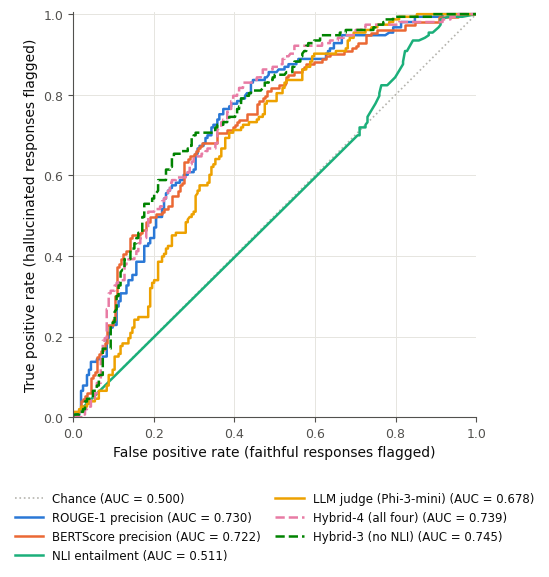

In [9]:
import os
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

FIG_DIR = f'{DRIVE_DIR}/figures'
os.makedirs(FIG_DIR, exist_ok=True)

# one fixed colour and label per system, reused in every figure
ORDER = ['rouge', 'bertscore', 'nli', 'llm', 'hybrid4', 'hybrid3']
LABELS = {'rouge': 'ROUGE-1 precision', 'bertscore': 'BERTScore precision', 'nli': 'NLI entailment',
          'llm': 'LLM judge (Phi-3-mini)', 'hybrid4': 'Hybrid-4 (all four)', 'hybrid3': 'Hybrid-3 (no NLI)'}
COLORS = {'rouge': '#2a78d6', 'bertscore': '#eb6834', 'nli': '#1baf7a',
          'llm': '#eda100', 'hybrid4': '#e87ba4', 'hybrid3': '#008300'}
STYLES = {'rouge': '-', 'bertscore': '-', 'nli': '-', 'llm': '-', 'hybrid4': '--', 'hybrid3': '--'}

plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'legend.fontsize': 8.5, 'xtick.labelsize': 9,
                     'ytick.labelsize': 9, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': '#52514e', 'axes.labelcolor': '#0b0b0b', 'text.color': '#0b0b0b',
                     'xtick.color': '#52514e', 'ytick.color': '#52514e', 'pdf.fonttype': 42})

def save(fig, name):
    for ext in ['png', 'pdf']:
        fig.savefig(f'{FIG_DIR}/{name}.{ext}', dpi=300, bbox_inches='tight')
    print('Saved', f'{FIG_DIR}/{name}.png and .pdf')

fig_df = pd.read_csv(f'{DRIVE_DIR}/comparative_aligned_scores_with_hybrids.csv')
fig_test = fig_df[fig_df['split'] == 'test']
assert len(fig_test) == 357

fig, ax = plt.subplots(figsize=(5.2, 6.0))
ax.plot([0, 1], [0, 1], color='#b5b4ae', linestyle=':', linewidth=1.2, label='Chance (AUC = 0.500)')
for s in ORDER:
    fpr, tpr, _ = roc_curve(fig_test['y'], fig_test[f'h_{s}'])
    auc = roc_auc_score(fig_test['y'], fig_test[f'h_{s}'])
    ax.plot(fpr, tpr, color=COLORS[s], linestyle=STYLES[s], linewidth=1.8, label=f'{LABELS[s]} (AUC = {auc:.3f})')
ax.set_xlabel('False positive rate (faithful responses flagged)')
ax.set_ylabel('True positive rate (hallucinated responses flagged)')
ax.set_xlim(0, 1); ax.set_ylim(0, 1.005)
ax.set_aspect('equal')
ax.grid(color='#e6e5e0', linewidth=0.7)
ax.set_axisbelow(True)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=2, frameon=False, columnspacing=1.2, handlelength=2.4)
save(fig, 'fig1_roc_curves_test')
plt.show()

### G2 — Per-task ROC-AUC with confidence intervals
Dot = point estimate, bar = 95% bootstrap interval, dotted line = chance (0.5). Two separate files: the held-out test set (primary) and all 1,781 responses (supplementary, not held-out). Supports two findings: no system is best in every task type, and NLI is at chance in all of them. Overlapping intervals do **not** show that two systems are equal, and non-overlapping ones are not a significance test; the paired tests are in section C.

Saved /content/drive/MyDrive/rag-eval-metrics/figures/fig2_per_task_roc_auc_test.png and .pdf


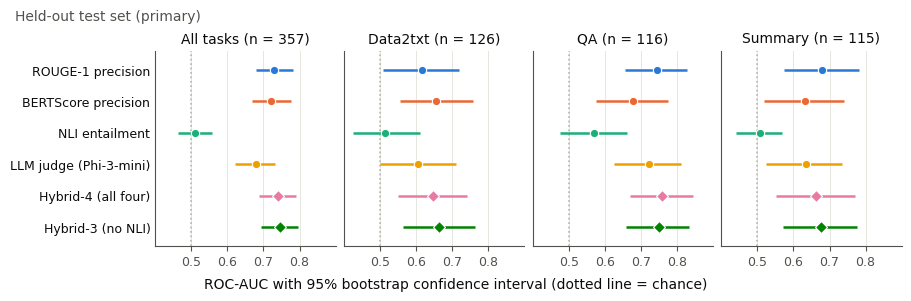

Saved /content/drive/MyDrive/rag-eval-metrics/figures/fig2s_per_task_roc_auc_all_supplementary.png and .pdf


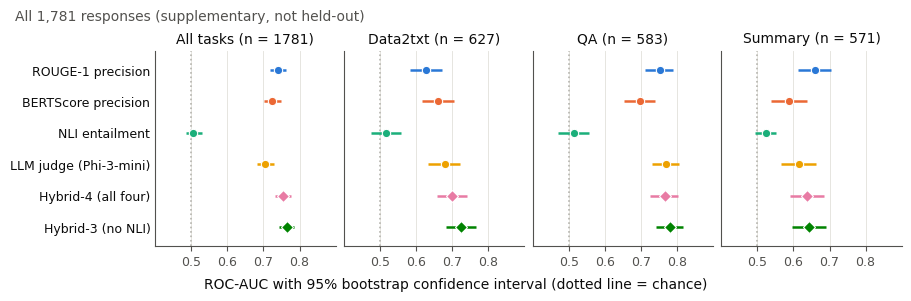

In [10]:
auc_fig = pd.read_csv(f'{DRIVE_DIR}/comparative_hybrid_auc_results.csv')
TASKS = ['All', 'Data2txt', 'QA', 'Summary']
MARKERS = {'rouge': 'o', 'bertscore': 'o', 'nli': 'o', 'llm': 'o', 'hybrid4': 'D', 'hybrid3': 'D'}

def per_task_figure(scope, heading, name):
    part = auc_fig[auc_fig['scope'] == scope]
    fig, axes = plt.subplots(1, 4, figsize=(9.0, 2.9), sharey=True, layout='constrained')
    ypos = {s: len(ORDER) - 1 - i for i, s in enumerate(ORDER)}
    for ax, task in zip(axes, TASKS):
        sub = part[part['task'] == task].set_index('system')
        ax.axvline(0.5, color='#b5b4ae', linestyle=':', linewidth=1.2)
        for s in ORDER:
            r = sub.loc[s]
            ax.errorbar(r['roc_auc'], ypos[s], xerr=[[r['roc_auc'] - r['roc_lo']], [r['roc_hi'] - r['roc_auc']]],
                        fmt=MARKERS[s], color=COLORS[s], markersize=6, markeredgecolor='white', markeredgewidth=0.8,
                        elinewidth=1.8, capsize=0)
        ax.set_title(f'{"All tasks" if task == "All" else task} (n = {int(sub["n"].iloc[0])})', fontsize=10)
        ax.set_xlim(0.40, 0.90)
        ax.set_xticks([0.5, 0.6, 0.7, 0.8])
        ax.set_ylim(-0.6, len(ORDER) - 0.4)
        ax.grid(axis='x', color='#e6e5e0', linewidth=0.7)
        ax.set_axisbelow(True)
        ax.tick_params(axis='y', length=0)
    axes[0].set_yticks([ypos[s] for s in ORDER])
    axes[0].set_yticklabels([LABELS[s] for s in ORDER], color='#0b0b0b')
    fig.supxlabel('ROC-AUC with 95% bootstrap confidence interval (dotted line = chance)', fontsize=10)
    fig.suptitle(heading, fontsize=10, x=0.01, ha='left', color='#52514e')
    save(fig, name)
    plt.show()

per_task_figure('test (primary)', 'Held-out test set (primary)', 'fig2_per_task_roc_auc_test')
per_task_figure('all 1781 (supplementary)', 'All 1,781 responses (supplementary, not held-out)', 'fig2s_per_task_roc_auc_all_supplementary')

### G3 — Held-out ROC-AUC against compute cost
ROUGE was never timed, so this cell first times it on the CPU runtime and checks that the recomputed scores are identical to the saved ones (no saved result is changed).

What the timings include:
- **ROUGE**: scoring ROUGE-1/2/L for all 1,781 responses on Colab CPU, timed here.
- **BERTScore**: the full `bert_score` call on a T4 GPU as recorded in notebook 01.
- **NLI**: inference over 13,548 sentence pairs on a T4 GPU as recorded in notebook 02 (sentence splitting not included).
- **LLM judge**: sum of per-response tokenisation + forward pass on a T4 GPU, recorded in notebook 03.
- **Hybrids**: the sum of their components; the rank-averaging step itself is negligible.

Not included for any system: package installation, model download and model loading. CPU seconds and GPU seconds are different resources, so the x-axis compares elapsed time, not cost in money or energy; marker shape shows the hardware. Timings are single runs on shared Colab hardware and will vary.

ROUGE (1, 2, L) on 1781 responses: 25.4 s on CPU | max difference from saved scores: 1.11e-16
   system                         hardware  seconds_for_1781_responses  ms_per_response  test_roc_auc
    rouge                         CPU only                        25.4             14.3         0.730
bertscore                           T4 GPU                       169.5             95.2         0.722
      nli                           T4 GPU                      1305.0            732.7         0.511
      llm                           T4 GPU                       914.3            513.4         0.678
  hybrid4 T4 GPU + CPU (sum of components)                      2414.2           1355.5         0.739
  hybrid3 T4 GPU + CPU (sum of components)                      1109.2            622.8         0.745
Saved /content/drive/MyDrive/rag-eval-metrics/figures/fig3_roc_auc_vs_compute_cost.png and .pdf


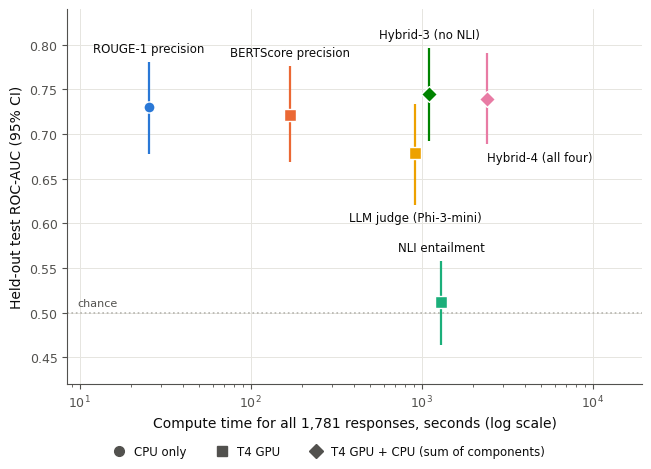

In [11]:
import subprocess, sys, time
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'rouge-score'], check=True)
from rouge_score import rouge_scorer
from matplotlib.lines import Line2D

# 1) Time ROUGE on this CPU runtime (it was never timed) and confirm it reproduces the saved scores
texts = pd.read_csv(f'{DRIVE_DIR}/ragtruth_eval_dataframe.csv', usecols=['id', 'source_info', 'response'])
scorer = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rougeL'], use_stemmer=True)
t0 = time.time()
rouge_now = [scorer.score(target=src, prediction=resp)['rouge1'].precision
             for src, resp in zip(texts['source_info'], texts['response'])]
rouge_seconds = time.time() - t0
saved_rouge = pd.read_csv(f'{DRIVE_DIR}/ragtruth_rouge_scores.csv', usecols=['id', 'rouge1_precision'])
check = texts[['id']].assign(now=rouge_now).merge(saved_rouge, on='id', validate='one_to_one')
max_diff = (check['now'] - check['rouge1_precision']).abs().max()
print(f'ROUGE (1, 2, L) on {len(texts)} responses: {rouge_seconds:.1f} s on CPU | max difference from saved scores: {max_diff:.2e}')
assert max_diff < 1e-9, 'Recomputed ROUGE does not match the saved scores'
pd.DataFrame([{'metric': 'rouge', 'device': 'cpu (Colab)', 'compute_time_seconds': round(rouge_seconds, 1),
               'note': 'timed in 04_comparative_analysis; scores identical to saved file'}]).to_csv(f'{DRIVE_DIR}/rouge_cpu_timing.csv', index=False)

# 2) Cost of each system (seconds for all 1,781 responses)
meta_c = pd.read_csv(f'{DRIVE_DIR}/metric_run_metadata.csv')
gpu = dict(zip(['rouge', 'bertscore', 'nli', 'llm'], meta_c['compute_time_seconds'].iloc[:4]))
cost_s = {'rouge': rouge_seconds, 'bertscore': gpu['bertscore'], 'nli': gpu['nli'], 'llm': gpu['llm'],
          'hybrid4': rouge_seconds + gpu['bertscore'] + gpu['nli'] + gpu['llm'],
          'hybrid3': rouge_seconds + gpu['bertscore'] + gpu['llm']}
HARDWARE = {'rouge': 'CPU only', 'bertscore': 'T4 GPU', 'nli': 'T4 GPU', 'llm': 'T4 GPU',
            'hybrid4': 'T4 GPU + CPU (sum of components)', 'hybrid3': 'T4 GPU + CPU (sum of components)'}
HW_MARKER = {'CPU only': 'o', 'T4 GPU': 's', 'T4 GPU + CPU (sum of components)': 'D'}

perf = pd.read_csv(f'{DRIVE_DIR}/comparative_hybrid_auc_results.csv')
perf = perf[(perf['scope'] == 'test (primary)') & (perf['task'] == 'All')].set_index('system')
cost_table = pd.DataFrame({'system': ORDER, 'hardware': [HARDWARE[s] for s in ORDER],
                           'seconds_for_1781_responses': [round(cost_s[s], 1) for s in ORDER],
                           'ms_per_response': [round(1000 * cost_s[s] / 1781, 1) for s in ORDER],
                           'test_roc_auc': [round(perf.loc[s, 'roc_auc'], 3) for s in ORDER]})
cost_table.to_csv(f'{DRIVE_DIR}/comparative_cost_table.csv', index=False)
print(cost_table.to_string(index=False))

# 3) Figure: held-out test ROC-AUC against compute time (log scale)
# label position: above the top of the interval, or below its bottom, so labels never sit on a bar
LABEL_POS = {'rouge': ('hi', 'center'), 'bertscore': ('hi', 'center'), 'nli': ('hi', 'center'),
             'llm': ('lo', 'center'), 'hybrid4': ('lo', 'left'), 'hybrid3': ('hi', 'center')}
fig, ax = plt.subplots(figsize=(6.4, 4.6), layout='constrained')
ax.axhline(0.5, color='#b5b4ae', linestyle=':', linewidth=1.2)
for s in ORDER:
    r = perf.loc[s]
    ax.errorbar(cost_s[s], r['roc_auc'], yerr=[[r['roc_auc'] - r['roc_lo']], [r['roc_hi'] - r['roc_auc']]],
                fmt=HW_MARKER[HARDWARE[s]], color=COLORS[s], markersize=8, markeredgecolor='white', markeredgewidth=1,
                elinewidth=1.6, capsize=0)
    end, ha = LABEL_POS[s]
    ax.annotate(LABELS[s], (cost_s[s], r['roc_hi'] if end == 'hi' else r['roc_lo']), xytext=(0, 5 if end == 'hi' else -5),
                textcoords='offset points', ha=ha, va='bottom' if end == 'hi' else 'top', fontsize=8.5, color='#0b0b0b')
ax.set_xscale('log')
ax.set_xlim(min(cost_s.values()) / 3, max(cost_s.values()) * 8)
ax.set_ylim(0.42, 0.84)
ax.set_xlabel('Compute time for all 1,781 responses, seconds (log scale)')
ax.set_ylabel('Held-out test ROC-AUC (95% CI)')
ax.grid(color='#e6e5e0', linewidth=0.7)
ax.set_axisbelow(True)
ax.text(ax.get_xlim()[0] * 1.15, 0.505, 'chance', fontsize=8, color='#52514e', va='bottom')
handles = [Line2D([], [], marker=m, linestyle='', color='#52514e', markersize=7, label=h) for h, m in HW_MARKER.items()]
fig.legend(handles=handles, loc='outside lower center', ncol=3, frameon=False, fontsize=8.5, handletextpad=0.3)
save(fig, 'fig3_roc_auc_vs_compute_cost')
plt.show()

In [12]:
import sys, platform, importlib.metadata as md

pkgs = ['numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib', 'torch', 'transformers',
        'accelerate', 'bert-score', 'rouge-score', 'nltk', 'tqdm']
lines = [f'python {sys.version.split()[0]} ({platform.platform()})']
for p in pkgs:
    try:
        lines.append(f'{p}=={md.version(p)}')
    except md.PackageNotFoundError:
        lines.append(f'{p}: not installed in this runtime')
print('\n'.join(lines))
open(f'{DRIVE_DIR}/environment_versions.txt', 'w').write('\n'.join(lines) + '\n')

python 3.13.16 (Linux-6.6.122+-x86_64-with-glibc2.39)
numpy==2.1.3
pandas==2.2.3
scipy==1.16.3
scikit-learn==1.6.1
matplotlib==3.10.0
torch==2.11.0+cpu
transformers==5.18.0
accelerate==1.15.0
bert-score: not installed in this runtime
rouge-score==0.1.2
nltk==3.9.1
tqdm==4.67.3


278